In [1]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset Shape: (1000, 9)
Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [1]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Rows:")
display(df.head())

NameError: name 'df' is not defined

In [2]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

print("CSV loaded successfully!")

CSV loaded successfully!


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (1000, 9)

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data Types:
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

First 5 Rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


# Exploratory Data Analysis on Retail Sales Data

## Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on a retail sales dataset to identify sales patterns, customer behaviour, product category performance, and useful business insights.

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Dataset
The dataset contains 1,000 retail transactions with information about:
- Transaction ID
- Date
- Customer ID
- Gender
- Age
- Product Category
- Quantity
- Price per Unit
- Total Amount

In [4]:
# Convert Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Check data types after conversion
print(df.dtypes)

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [5]:
# Check duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [6]:
# Select numerical columns
numeric_columns = df.select_dtypes(include='number').columns

# Mean
mean_values = df[numeric_columns].mean()

# Median
median_values = df[numeric_columns].median()

# Mode
mode_values = df[numeric_columns].mode().iloc[0]

# Standard deviation
std_values = df[numeric_columns].std()

# Create summary table
statistics = pd.DataFrame({
    'Mean': mean_values,
    'Median': median_values,
    'Mode': mode_values,
    'Standard Deviation': std_values
})

statistics

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.500,500.5,1.0,288.819436
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


### Observation

The descriptive statistics provide an overview of the numerical variables in the dataset. The mean and median help understand the central tendency, while standard deviation indicates the amount of variation in each variable. The statistics for Total Amount and Quantity are particularly useful for understanding customer spending and purchasing behaviour.

In [7]:
# Extract month from Date
df['Month'] = df['Date'].dt.to_period('M').astype(str)

# Calculate monthly sales
monthly_sales = df.groupby('Month')['Total Amount'].sum()

monthly_sales

Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Name: Total Amount, dtype: int64

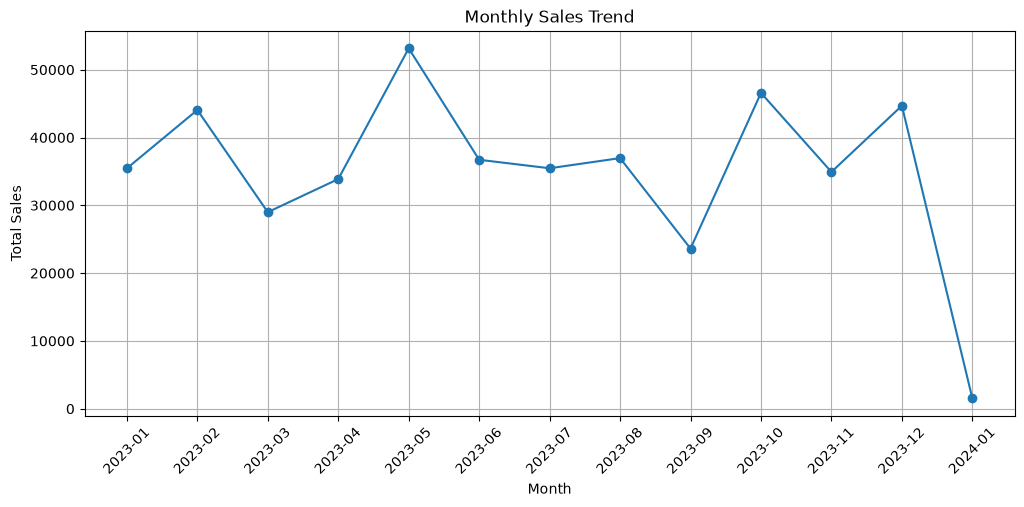

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

### Observation

The monthly sales trend shows how total sales changed throughout the year. The highest points represent months with stronger sales performance, while lower points indicate comparatively weaker sales periods. This trend can help businesses identify high-demand and low-demand months for inventory and marketing planning.

In [9]:
# Extract quarter from Date
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)

# Calculate quarterly sales
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

quarterly_sales

Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Name: Total Amount, dtype: int64

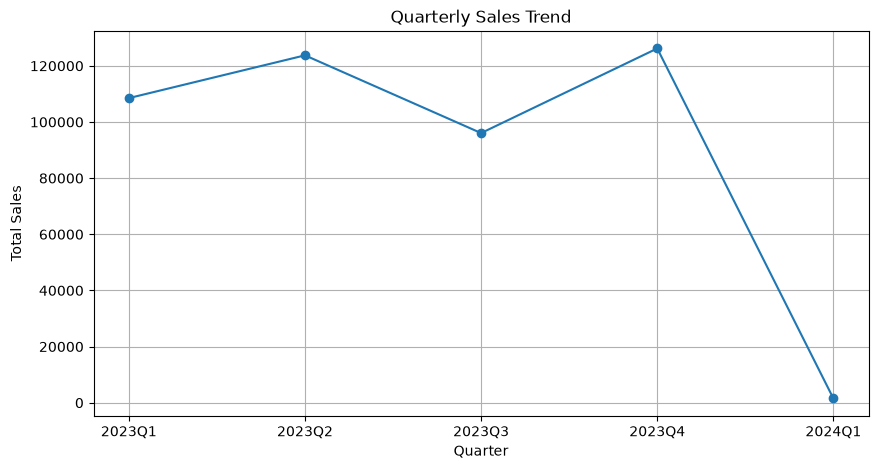

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker='o'
)

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.grid(True)

plt.show()

### Observation

The quarterly sales analysis provides a broader view of business performance than monthly analysis. It helps identify which quarters generated higher revenue and can support quarterly sales planning, budgeting, inventory management, and promotional strategies.

In [11]:
# Create age groups
bins = [0, 18, 25, 35, 45, 55, 65, 100]

labels = [
    'Below 18',
    '18-25',
    '26-35',
    '36-45',
    '46-55',
    '56-65',
    '65+'
]

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Count customers in each age group
age_group_counts = df['Age Group'].value_counts().sort_index()

age_group_counts

Age Group
Below 18     21
18-25       148
26-35       205
36-45       202
46-55       229
56-65       195
65+           0
Name: count, dtype: int64

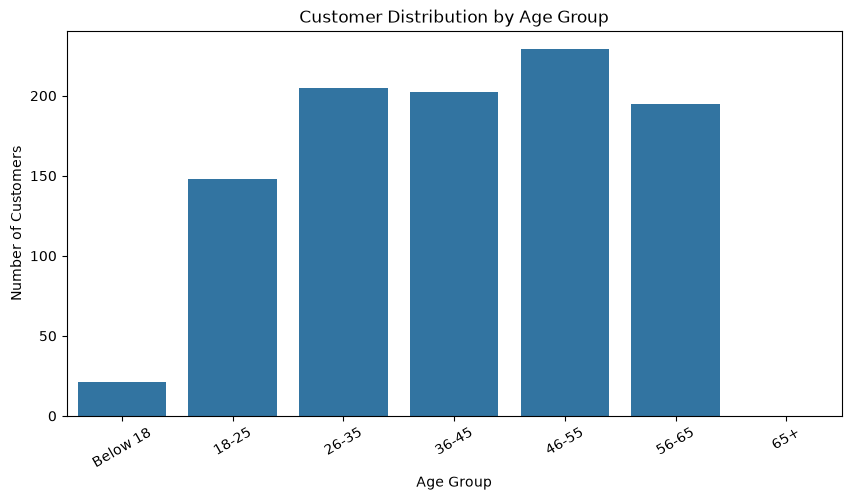

In [12]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=age_group_counts.index,
    y=age_group_counts.values
)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)

plt.show()

### Observation

The age-group distribution shows which customer age groups are most represented in the dataset. Understanding the dominant age groups can help businesses design targeted marketing campaigns, product promotions, and customer engagement strategies.

In [13]:
gender_counts = df['Gender'].value_counts()

gender_counts

Gender
Female    510
Male      490
Name: count, dtype: int64

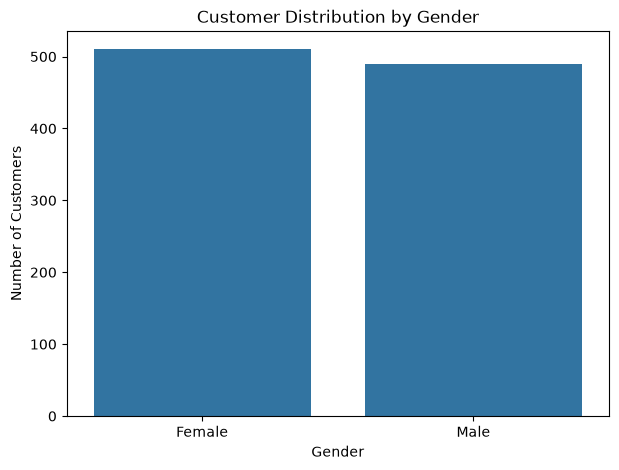

In [14]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values
)

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

### Observation

The gender distribution shows the number of transactions made by male and female customers. This information can help businesses understand their customer base and develop suitable marketing and promotional strategies.

In [15]:
category_revenue = (
    df.groupby('Product Category')['Total Amount']
    .sum()
    .sort_values(ascending=False)
)

category_revenue

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

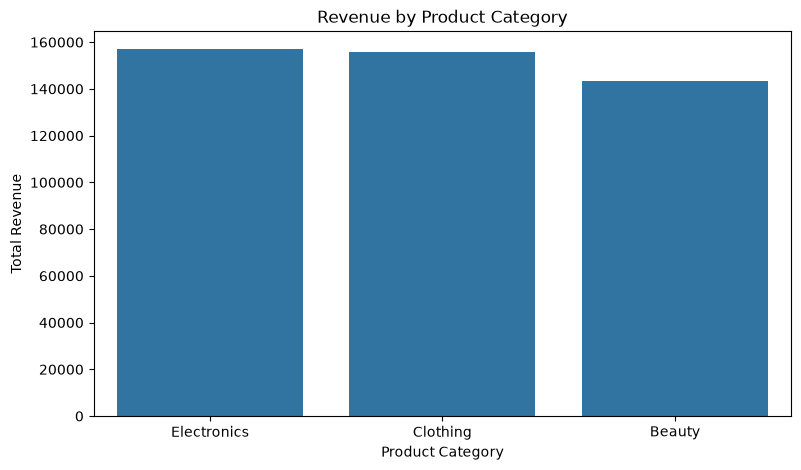

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.show()

### Observation

The revenue analysis shows which product categories contribute the most to total sales. Higher-revenue categories are important for inventory planning, promotions, and business investment. Lower-performing categories may require additional marketing or pricing strategies.

In [17]:
top_categories = (
    df.groupby('Product Category')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

top_categories

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

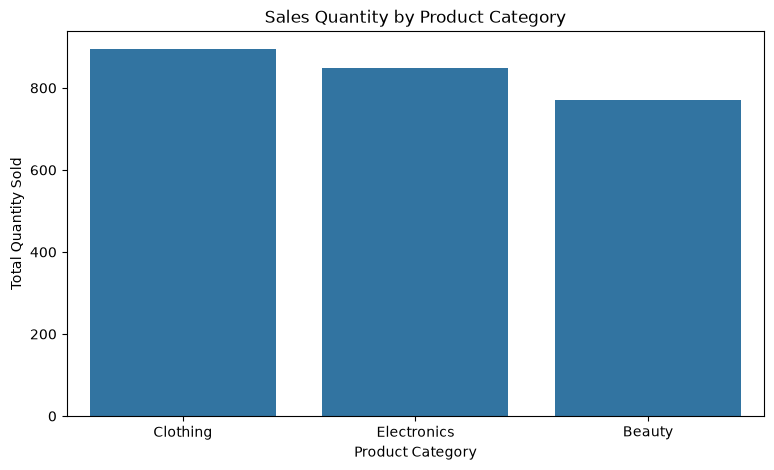

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=top_categories.index,
    y=top_categories.values
)

plt.title('Sales Quantity by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')

plt.show()

### Observation

The quantity analysis identifies the product categories with the highest number of units sold. Categories with high quantities indicate strong customer demand and may require better inventory availability.

In [19]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

correlation_matrix

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
Transaction ID,1.000000,0.065191,-0.026623,-0.060837,-0.075034
Age,0.065191,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.026623,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.060837,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.075034,-0.060568,0.373707,0.851925,1.000000


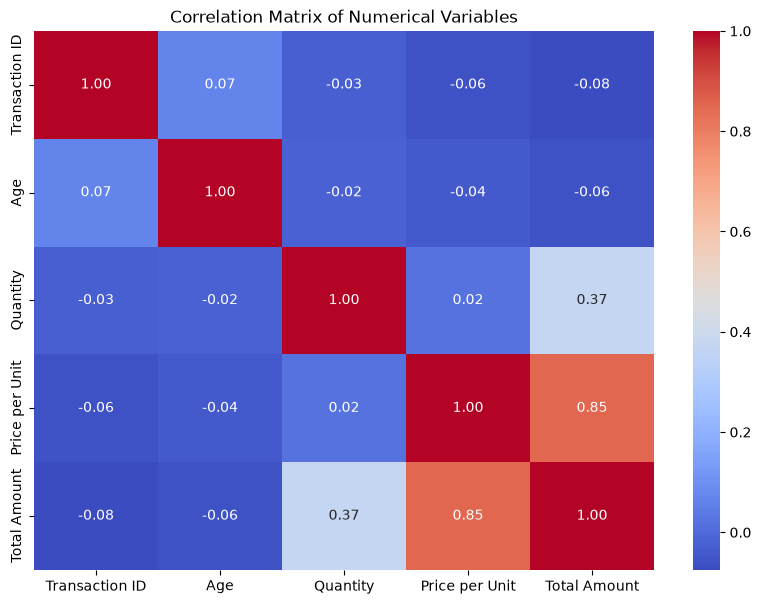

In [20]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Variables')

plt.show()

### Observation

The correlation heatmap shows the relationships between numerical variables. A value close to +1 indicates a strong positive relationship, while a value close to -1 indicates a strong negative relationship. Values near 0 indicate a weak relationship.

The relationship between Quantity, Price per Unit, and Total Amount is particularly useful for understanding how transaction characteristics affect sales revenue.

In [21]:
age_group_spending = (
    df.groupby('Age Group', observed=True)['Total Amount']
    .mean()
)

age_group_spending

Age Group
Below 18    534.047619
18-25       495.506757
26-35       480.390244
36-45       454.801980
46-55       439.694323
56-65       412.358974
Name: Total Amount, dtype: float64

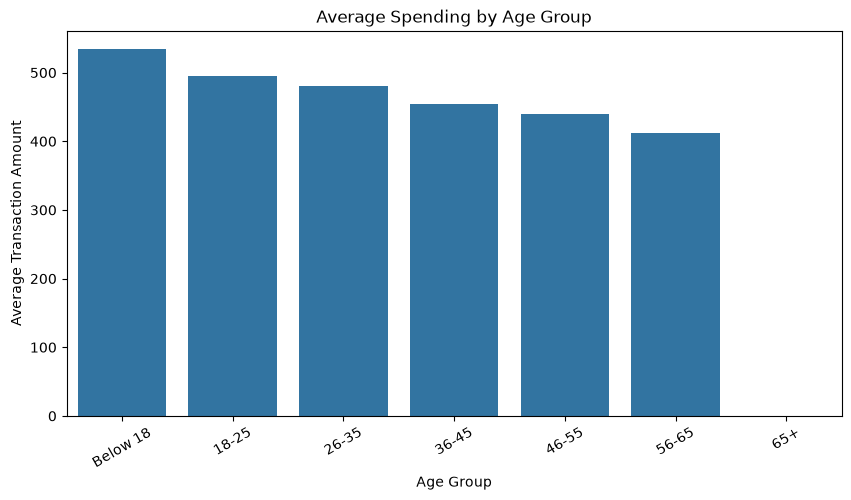

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=age_group_spending.index,
    y=age_group_spending.values
)

plt.title('Average Spending by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=30)

plt.show()

### Observation

The average spending analysis provides a deeper understanding of customer behaviour. A particular age group may have fewer transactions but a higher average transaction value. This indicates that customer count alone does not always represent customer value.

# Key Business Insights

Based on the exploratory data analysis, the following insights can be identified:

1. **Sales Trends:** Monthly and quarterly analysis helps identify periods of high and low sales performance.

2. **Customer Demographics:** Age-group and gender analysis provides an understanding of the major customer segments.

3. **Product Categories:** Some product categories generate more revenue and/or have higher sales quantities than others.

4. **Customer Spending:** Average transaction value differs across age groups, showing that customer frequency and customer value are not always the same.

5. **Variable Relationships:** The correlation heatmap helps identify relationships between quantity, price, and total transaction amount.

6. **Inventory Planning:** High-demand product categories should be monitored carefully to reduce the possibility of stock shortages.

# Conclusion and Business Recommendations

## Conclusion

The Exploratory Data Analysis of the retail sales dataset helped identify sales trends, customer demographics, product category performance, and relationships between numerical variables. The analysis provides useful information that can support data-driven retail business decisions.

## Actionable Business Recommendations

### 1. Improve Inventory Planning
Businesses should maintain sufficient inventory for high-demand product categories to avoid stock shortages during strong sales periods.

### 2. Use Targeted Marketing
Marketing campaigns should be customized according to customer age groups and gender segments to improve customer engagement and campaign effectiveness.

### 3. Plan Promotions According to Sales Trends
High-performing months and quarters can be used for major promotional campaigns, while low-sales periods can be targeted with discounts and special offers.

### 4. Focus on High-Revenue Categories
Product categories generating higher revenue should receive appropriate inventory, marketing, and business investment.

### 5. Identify High-Value Customers
Average spending by age group can help businesses identify customer segments that generate higher transaction values and design suitable loyalty or premium offers.

> Note: The selected dataset contains product categories but does not contain individual product names. Therefore, the top-selling product analysis was performed at the product-category level.

# Project Summary

This project performed Exploratory Data Analysis (EDA) on 1,000 retail transactions using Python, Pandas, Matplotlib, and Seaborn.

The analysis covered:
- Dataset inspection and data quality checking
- Descriptive statistics
- Monthly and quarterly sales trends
- Customer age-group analysis
- Gender distribution
- Product-category revenue analysis
- Product-category quantity analysis
- Correlation analysis
- Average spending by age group
- Business insights and recommendations

The findings can help a retail business improve inventory planning, customer targeting, promotional strategies, and revenue-focused decision making.